<a href="https://colab.research.google.com/github/ashsiendo/DATA-201-Project1/blob/main/Project_1_Bank_Marketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project 1** - Ash Ibasan

The focus of this project is classification using the bank marketing dataset. I will compare logistic regression, LDA, QDA, and KNN to predict whether a customer will subscribe to a term deposit.

I will also consider the trade-off between contacting customers unlikely to subscribe and missing customers who would have subscribed, rather than focusing solely on accuracy.

> ***Note to self: Comments throughout are used as guides, mainly for Python syntax and reasons why certain steps are used.***

## **Setup**
*Import libraries needed for the project and load the bank marketing dataset*

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

In [24]:
bank = pd.read_csv("https://raw.githubusercontent.com/ashsiendo/DATA-201-Project1/refs/heads/main/bank-full.csv", sep=";") # sep=";" tells pandas that columns are separated by semicolons

## **Part 1 - Understand the Problem**
*Identify what the data represents, what I am predicting, and the consequences of incorrect predictions*

In [25]:
bank.shape # 45,211 observations, 17 columns

(45211, 17)

In [26]:
bank["y"].value_counts()

,count
y,
no,39922
yes,5289


**`y` has two classes: `yes` = subscribed, and `no` = did not subscribe**

In [27]:
bank["y"].value_counts(normalize=True) * 100 # proportions converted to percentages

,proportion
y,
no,88.30152
yes,11.69848


The dataset contains 45,211 observations and 17 columns, including `y`, the response variable. Each row contains recorded client characteristics, campaign information, and whether the client subscribed to the term deposit. `y` has two classes: `yes` and `no`; I will treat `yes` as the positive class.

About 88.3% of observations are `no` and 11.7% are `yes`; therefore, the response is imbalanced, and accuracy alone could be misleading. A model that predicts `no` for every customer would already be about 88.3% accurate, but would fail to identify any actual subscribers.

In [28]:
majority_class = bank["y"].value_counts().idxmax() # majority-class baseline
baseline_accuracy = bank["y"].value_counts(normalize=True).max()

print("Majority class:", majority_class)
print("Baseline accuracy:", round(baseline_accuracy, 4))

Majority class: no
Baseline accuracy: 0.883


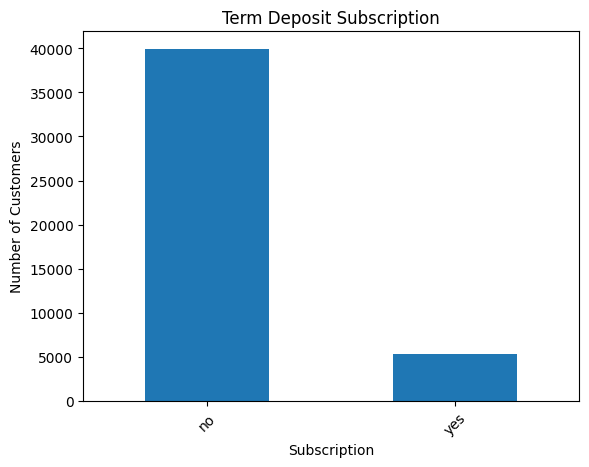

In [29]:
bank["y"].value_counts().plot(kind="bar")

plt.title("Term Deposit Subscription")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45) # rotates x-axis labels 45 degrees
plt.show()

The bar chart confirms the class imbalance, with the `no` class much larger than the `yes` class.

### **Prediction Scenario**

**The model will be framed as a pre-contact targeting tool:**
> *Before contacting a customer, can the bank identify customers who are more likely to subscribe to a term deposit?*

I only want to use information the bank would already know at that point because the prediction happens before the customer is contacted; for example, `duration` records how long the current contact lasted, so it would not be available yet and will be excluded.

### **Predictor Selection**

I will focus on variables that could realistically be known before contact, such as customer characteristics, financial information, and previous campaign history.

I will then explore the predictors more closely later on before deciding on the final set. The main aspects I will consider are whether the variable is available before contact, the data are usable, and if the variable seems relevant to predicting subscription.

### **False Positives, False Negatives, and Trade-offs**

Keep in mind, `yes` is the positive class.

A **false positive** occurs when the model predicts that a customer will subscribe, but they don't. The bank may spend time and resources contacting someone unlikely to subscribe.

A **false negative** happens when the model predicts that a customer will not subscribe, but they did. If the bank relies on this prediction to choose whom to contact, it might miss out on a potential subscriber.

Both types of errors are important, but I will focus on reducing false negatives first since the main goal is to find potential subscribers. Reaching out to more customers might also lead to more false positives, so I will keep both missed opportunities and unnecessary outreach in mind when comparing models. The dataset does not include the exact costs of these errors.

## **Part 2 - Data Exploration and Preparation**

*Inspect the predictors, variable types, and data quality, then prepare the data for modeling*

In [30]:
bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [31]:
bank.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


### **Missing Information and Data Quality**
*Check missing values, unknown categories, and repeated rows before deciding how to handle them*

In [32]:
bank.isna().sum()  # count pandas missing values in each column

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [33]:
(bank == "unknown").sum() # count literal "unknown" entries; these are not NaNs

,0
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day,0


In [34]:
bank.duplicated().sum() # count rows that are exact duplicates

np.int64(0)

`pandas` does not identify any missing values, and there are no exact duplicate rows, although `"unknown"` appears in the `job` category (288 times), `education` (1,857 times), `contact` (13,020 times), and `poutcome` (36,959 times).

The information in these categories is unknown or not available, and therefore the absence of `NaN` values doesn't imply all the values are known; I will look into what these values mean before determining how to deal with them.

In [35]:
bank["pdays"].value_counts().head(10) # show 10 most frequent values

,count
pdays,
-1,36954
182,167
92,147
183,126
91,126
181,117
370,99
184,85
364,77


`-1` in `pdays` means the client was not previously contacted in a previous campaign; `-1` is considered as a special code rather than an actual number of days. Treating it as an ordinary day count could mislead a distance-based model such as KNN.

In [36]:
pd.crosstab(bank["pdays"] == -1, bank["poutcome"]) # True means pdays = -1; compare this group with previous campaign outcomes

poutcome,failure,other,success,unknown
pdays,,,,
False,4901,1840,1511,5
True,0,0,0,36954


There are `36,954` cases where `pdays` is -1, and all of these have an `"unknown"` outcome from the previous campaign. Only five cases with a different `pdays` value have an unknown outcome.

The fact that this is the case suggests that the vast majority of previous outcomes that are `"unknown"` probably reflect no earlier campaign contact, since most of those observations also have `pdays = -1`; therefore, I'll include these cases and regard `"unknown"` as a separate category in `poutcome`.


### **Numerical Summary**
*Examine the ranges and spread of numeric variables, keeping special codes and prediction timing in mind*

In [37]:
bank.describe().T  # transpose so each variable is a row

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


The numeric variables vary a lot in their ranges. For example, the mean `balance` is much higher than the median, and some values are very large, suggesting a right skew. The counts for `campaign` and `previous` contacts also have values well above their upper quartiles.

These extreme values should be checked, but I won't remove them just because they are large. The summary for `pdays` also uses the special code `-1`, so the mean doesn't only reflect clients who had previous contact.

***Note to self:*** scaling is important for KNN because variables with larger ranges can have a bigger impact on distance calculations. However, scaling does not solve skewness or deal with special codes.


In [38]:
bank.nlargest(5, "previous")[["previous", "pdays", "poutcome", "campaign"]] # inspect five largest previous-contact counts alongside campaign history

,previous,pdays,poutcome,campaign
29182,275,262,other,2
38326,58,353,other,2
44089,55,776,failure,3
28886,51,256,failure,3
44822,41,778,other,1


The highest `previous`-contact count is 275, while the next highest is 58. This value stands out as unusually high, but I don't have enough evidence to call it an error. For now, I'll keep it and take its possible impact into account during modeling.

In [39]:
bank.describe(include="object").T # summarize categorical columns, categories, and most common values

,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


The categorical predictors include binary variables like `housing` and `loan`, as well as variables with several categories, such as `job` and `education`. These categories need to be converted into numbers before modeling.

***Note to self:*** Assigning random numbers to categories like `job` might suggest an order or distance that is not really there. One-hot encoding can solve this by using separate columns for each category. The response variable `y` will be managed separately from the predictors.

### **Initial Predictor Set**
*Select client characteristics, financial information, and previous campaign history that could be available before contact*

At first, I will leave out `duration`, `contact`, `day`, `month`, and `campaign`. These features describe the current campaign’s contact activity, and including them would mean making more assumptions about what is known at prediction time. I will also leave out `pdays` for now, since its -1 code needs to be handled separately. The features `previous` and `poutcome` will still give information about previous campaigns, but by excluding `pdays`, we lose details about how recently a client was last contacted.

I'll continue to use `"unknown"` as a category at this stage than be treated as a missing value.

In [40]:
predictors = [ # predictors kept for pre-contact model
    "age", "job", "marital", "education",
    "default", "balance", "housing", "loan",
    "previous", "poutcome"
]

X = bank[predictors] # features used to make predictions
y = bank["y"] # response: whether the customer subscribed

X.shape

(45211, 10)

### **Training and Test Sets**
*Reserve 25% of the data for final testing and use the remaining 75% for training and cross-validation*

I'll use the same data split for all four models, and stratification helps make sure that the subscription classes are represented in similar proportions in both sets.

In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=12, # makes the split reproducible
    stratify=y # preserves approximate class proportions
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (33908, 10)
Testing: (11303, 10)


### **Encoding and Standardization**
*Convert categorical predictors into numbers and standardize numeric predictors as part of the modeling pipeline*

Categorical predictors need to be converted to numbers. For all four models, I will use the same preprocessing steps: one-hot encoding for categorical predictors and standardizing numeric predictors. Scaling is especially important for KNN since bigger numbers can skew distance calculations. I will fit the preprocessing within each cross-validation training fold.

In [42]:
num_features = ["age", "balance", "previous"]

cat_features = [
    "job", "marital", "education",
    "default", "housing", "loan", "poutcome"
]

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# define steps here; fitting happens later inside the model pipelines

preprocessor = ColumnTransformer( # apply different preprocessing to numeric and categorical columns; each tuple contains step name, transformer, columns
    transformers=[
        ("numeric", StandardScaler(), num_features),
        ("categorical", OneHotEncoder(
            drop="first", # leave one category out as reference
            handle_unknown="ignore", # unseen categories become all zeroes for that feature
            sparse_output=False # return regular array
        ), cat_features)
    ]
)

### **Cross-Validation Setup**
*To test all four classifiers, divide the training data into five stratified folds*




The different subscription classes are maintained in roughly the same proportions in each fold, and I'll use the same folds for each model so that the comparisons remain consistent.

***Note to self:*** the pipeline should carry out encoding and scaling only on the training portion of each fold, and the test set should be kept for the final evaluation.

In [44]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=12
)

## **Part 3 - Build Classifiers**
*Take the training data and apply 5-fold cross-validation to compare Logistic Regression, LDA, QDA, and KNN. Make sure the same preprocessing steps, folds, and scoring metric are used for all models*

Since the response is imbalanced, I will use ROC-AUC as the main cross-validation metric instead of accuracy. ROC-AUC shows how well a model ranks positive and negative classes at different thresholds.

For all four models, I will employ the same 5-fold stratified cross-validation procedure and the test set will be used merely for the final evaluation and not for selecting or tuning the models.

In [47]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from sklearn.neighbors import KNeighborsClassifier

### **Logistic Regression**
*The first model to be evaluated is logistic regression; the same predictors, the same preprocessing steps, 5-fold cross-validation, and ROC-AUC scoring will be used*

In [85]:
# build pipeline so preprocessing happens inside each CV training fold
lr_model = make_pipeline(
    preprocessor,
    LogisticRegression(max_iter=1000) # max_iter gives model more chances to converge if default limit is not enough
)

# evaluate logistic regression using only training data
lr_cv = cross_val_score(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("LR CV AUC scores:", lr_cv.round(4))
print("LR average CV AUC:", round(lr_cv.mean(), 4))

LR CV AUC scores: [0.707  0.7145 0.7151 0.7019 0.7113]
LR average CV AUC: 0.7099


### **LDA**
*LDA will use the same predictors, preprocessing method, CV folds, and ROC-AUC scoring as LR so the two models can be compared consistently*

In [55]:
lda_model = make_pipeline( # use same preprocessing and folds as LR
    preprocessor,
    LinearDiscriminantAnalysis()
)

lda_cv = cross_val_score(
    lda_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("LDA CV AUC scores:", lda_cv.round(4))
print("LDA average CV AUC:", round(lda_cv.mean(), 4))

LDA CV AUC scores: [0.7065 0.7137 0.7142 0.7007 0.7097]
LDA average CV AUC: 0.709


### **QDA**
*To ensure a consistent comparison with LR and LDA, QDA will use the same predictors, preprocessing steps, CV folds, and ROC-AUC scoring*

In [86]:
qda_model = make_pipeline( # QDA estimates separate covariance matrix for each class
    preprocessor,
    QuadraticDiscriminantAnalysis()
)

qda_cv = cross_val_score(
    qda_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("QDA CV AUC scores:", qda_cv.round(4))
print("QDA average CV AUC:", round(qda_cv.mean(), 4))

QDA CV AUC scores: [0.697  0.6918 0.6714 0.6833 0.6971]
QDA average CV AUC: 0.6881


QDA achieved an average cross-validation AUC of `0.6881`, lower than LR's `0.7099`. The added flexibility in QDA’s decision boundary didn't improve ranking performance with these predictors.

### **KNN**
*KNN differs from the other classifiers because it requires choosing the number of neighbors, `k`. I will test several `k` values, using the same training data, 5-fold cross-validation, and ROC-AUC scoring*

In [83]:
from sklearn.model_selection import GridSearchCV

knn_model = make_pipeline( # build KNN pipeline so preprocessing happens inside each CV fold
    preprocessor,
    KNeighborsClassifier()
)

knn_grid = {
    "kneighborsclassifier__n_neighbors": [1, 3, 5, 11, 21, 51, 75, 101, 151, 201, 301, 501, 751, 1001],
    "kneighborsclassifier__weights": ["uniform", "distance"]
}

knn_search = GridSearchCV( # tune KNN using same CV folds and ROC-AUC metric
    knn_model,
    knn_grid,
    cv=cv,
    scoring="roc_auc"
)

knn_search.fit(X_train, y_train) # run grid search using only training data; test data stays untouched

print("Best k:", knn_search.best_params_["kneighborsclassifier__n_neighbors"])
print("Best weights:", knn_search.best_params_["kneighborsclassifier__weights"])
print("KNN best average CV AUC:", round(knn_search.best_score_, 4))

Best k: 501
Best weights: uniform
KNN best average CV AUC: 0.7104


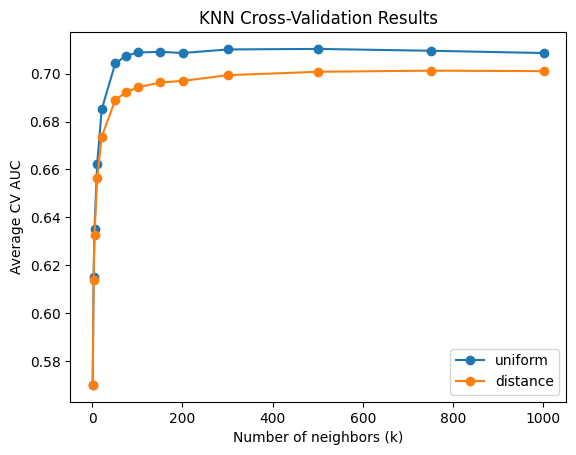

In [84]:
knn_results = pd.DataFrame(knn_search.cv_results_)

for weight in ["uniform", "distance"]: # plot each voting method separately in order of k
    results = knn_results[
        knn_results["param_kneighborsclassifier__weights"] == weight
    ].sort_values("param_kneighborsclassifier__n_neighbors")

    plt.plot(
        results["param_kneighborsclassifier__n_neighbors"].astype(int),
        results["mean_test_score"],
        marker="o",
        label=weight
    )

plt.xlabel("Number of neighbors (k)")
plt.ylabel("Average CV AUC")
plt.title("KNN Cross-Validation Results")
plt.legend()
plt.show()

I expanded the range of `k` since the highest value at first yielded the best results. When I tested selected values up to 1001, $ k=501 $ gave the highest average CV AUC (`0.7104`), so I decided to use it in the final evaluation.

### **Final Model Fitting and Test Predictions**

In [87]:
# fit three untuned models on full training set
lr_model.fit(X_train, y_train)
lda_model.fit(X_train, y_train)
qda_model.fit(X_train, y_train)

# GridSearchCV already refit best KNN model on all training data
knn_final = knn_search.best_estimator_

# check class order (no/yes) before selecting positive-class probability
print("Class order:", lr_model.classes_)

Class order: ['no' 'yes']


In [88]:
# predicted class labels for test set
lr_pred = lr_model.predict(X_test)
lda_pred = lda_model.predict(X_test)
qda_pred = qda_model.predict(X_test)
knn_pred = knn_final.predict(X_test)

# predicted probabilities for positive class ("yes")
lr_prob = lr_model.predict_proba(X_test)[:, 1]
lda_prob = lda_model.predict_proba(X_test)[:, 1]
qda_prob = qda_model.predict_proba(X_test)[:, 1]
knn_prob = knn_final.predict_proba(X_test)[:, 1]

## Part 4 - Evaluate Classifier Performance

## Part 5 - Reflection

## Part 6 - ROC and AUC

## Part 7 - Final Analysis